**Настройка**

In [1]:
%pip -q install nvidia-ml-py
import gc, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.optimize import least_squares
import pynvml as nvml

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.manual_seed(2026)
nvml.nvmlInit()
gpu = nvml.nvmlDeviceGetHandleByIndex(0)
Path('results/figures').mkdir(parents=True, exist_ok=True)
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('CUDA:', torch.version.cuda)
print('cuDNN:', torch.backends.cudnn.version())


GPU: Tesla T4
PyTorch: 2.11.0+cu130
CUDA: 13.0
cuDNN: 92700


**Сеть**

In [2]:
model = nn.Sequential(
    nn.Conv2d(3, 32, 7, stride=2, padding=3, bias=False), nn.ReLU(inplace=True),
    nn.MaxPool2d(3, stride=2, padding=1),
    nn.Conv2d(32, 64, 5, padding=2, bias=False), nn.ReLU(inplace=True),
    nn.Conv2d(64, 128, 3, stride=2, padding=1, bias=False), nn.ReLU(inplace=True),
    nn.Conv2d(128, 256, 1, bias=False), nn.ReLU(inplace=True),
    nn.Conv2d(256, 256, 3, stride=2, padding=1, bias=False), nn.ReLU(inplace=True),
    nn.Conv2d(256, 512, 1, bias=False), nn.ReLU(inplace=True),
    nn.AdaptiveAvgPool2d(1), nn.Flatten(),
    nn.Linear(512, 256), nn.ReLU(inplace=True), nn.Linear(256, 100)
).float().cuda().eval()


**Формулы**

In [3]:
def flops(S, B):
    return np.asarray(B) * (17714 * np.asarray(S)**2 + 313700)

def memory(S, B):
    return 4161296 + 68 * np.asarray(B) * np.asarray(S)**2

def bytes_moved(S, B):
    return 4 * (1040324 + 95 * np.asarray(B) * np.asarray(S)**2 + 2148 * np.asarray(B))

def latency(S, B, theta):
    tau, compute, bandwidth = theta
    return tau + np.maximum(flops(S, B) / compute, bytes_moved(S, B) / bandwidth)

def energy(S, B, theta_energy):
    return theta_energy[3] * latency(S, B, theta_energy[:3])


**Сетка**

In [4]:
rng = np.random.default_rng(2026)
base_S = [32, 64, 128, 224, 256, 384, 512]
base_B = [1, 2, 4, 8, 16, 32, 64, 128, 256]
extra_S = rng.choice([s for s in range(32, 513, 16) if s not in base_S], 4, replace=False)
extra_B = rng.choice([b for b in range(1, 257) if b not in base_B], 3, replace=False)
sizes = sorted(base_S + extra_S.tolist())
batches = sorted(base_B + extra_B.tolist())
grid = [(s, b) for s in sizes for b in batches]
rng.shuffle(grid)
print('S:', sizes, '\nB:', batches)


S: [32, 48, 64, 112, 128, 224, 256, 352, 384, 400, 512] 
B: [1, 2, 4, 8, 16, 32, 64, 95, 98, 128, 167, 256]


**Измерения**

In [5]:
def count_flops(x):
    counts = []
    def count_layer(layer, inputs, output):
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            operations = 2 * output.numel() * layer.weight[0].numel()
            if layer.bias is not None:
                operations += output.numel()
            counts.append(operations)
        elif isinstance(layer, nn.AdaptiveAvgPool2d):
            counts.append(inputs[0].numel())
    hooks = [layer.register_forward_hook(count_layer) for layer in model]
    try:
        model(x)
        torch.cuda.synchronize()
    finally:
        for hook in hooks:
            hook.remove()
    return sum(counts)

def measure_energy(x, latency_seconds):
    repeats_per_sample = max(1, round(0.05 / latency_seconds))
    times = [time.perf_counter()]
    powers = [nvml.nvmlDeviceGetPowerUsage(gpu) / 1000]
    passes = 0
    while times[-1] - times[0] < 2:
        for _ in range(repeats_per_sample):
            y = model(x)
            torch.cuda.synchronize()
            del y
        passes += repeats_per_sample
        powers.append(nvml.nvmlDeviceGetPowerUsage(gpu) / 1000)
        times.append(time.perf_counter())
    average_powers = (np.array(powers[1:]) + powers[:-1]) / 2
    joules = np.sum(average_powers * np.diff(times))
    return joules / passes

@torch.inference_mode()
def measure(S, B):
    x = torch.randn(B, 3, S, S, device='cuda', dtype=torch.float32)
    f = count_flops(x)
    for _ in range(5):
        model(x)
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    y = model(x)
    torch.cuda.synchronize()
    peak = torch.cuda.max_memory_allocated()
    del y
    times = []
    for _ in range(15):
        torch.cuda.synchronize()
        start = time.perf_counter()
        y = model(x)
        torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
        del y
    dt = float(np.median(times))
    return dict(flops=f, memory=peak, latency=dt, energy=measure_energy(x, dt))

rows = []
for i, (S, B) in enumerate(grid, 1):
    gc.collect()
    torch.cuda.empty_cache()
    free, _ = torch.cuda.mem_get_info()
    budget = free + torch.cuda.memory_allocated()
    row = dict(S=S, B=B, is_validation=S not in base_S or B not in base_B,
               predicted_oom=bool(memory(S, B) > budget), status='ok')
    try:
        row.update(measure(S, B))
    except torch.cuda.OutOfMemoryError:
        row['status'] = 'OOM'
    rows.append(row)
    pd.DataFrame(rows).to_csv('results/measurements.csv', index=False)
    print(f'{i}/132: S={S}, B={B}, {row["status"]}')
df = pd.DataFrame(rows)


1/132: S=64, B=95, ok
2/132: S=32, B=167, ok
3/132: S=128, B=1, ok
4/132: S=352, B=128, ok
5/132: S=400, B=8, ok
6/132: S=224, B=256, ok
7/132: S=48, B=95, ok
8/132: S=48, B=64, ok
9/132: S=224, B=98, ok
10/132: S=48, B=32, ok
11/132: S=224, B=167, ok
12/132: S=352, B=167, ok
13/132: S=400, B=4, ok
14/132: S=112, B=98, ok
15/132: S=128, B=167, ok
16/132: S=48, B=1, ok
17/132: S=512, B=64, ok
18/132: S=384, B=16, ok
19/132: S=256, B=16, ok
20/132: S=48, B=16, ok
21/132: S=32, B=128, ok
22/132: S=224, B=95, ok
23/132: S=48, B=4, ok
24/132: S=400, B=16, ok
25/132: S=512, B=95, ok
26/132: S=512, B=256, ok
27/132: S=32, B=32, ok
28/132: S=400, B=2, ok
29/132: S=512, B=32, ok
30/132: S=256, B=64, ok
31/132: S=224, B=4, ok
32/132: S=224, B=1, ok
33/132: S=256, B=256, ok
34/132: S=256, B=98, ok
35/132: S=384, B=4, ok
36/132: S=64, B=2, ok
37/132: S=112, B=16, ok
38/132: S=112, B=256, ok
39/132: S=512, B=128, ok
40/132: S=352, B=8, ok
41/132: S=64, B=128, ok
42/132: S=512, B=1, ok
43/132: S=352

**Параметры**

In [6]:
valid = df[df.status == 'ok'].copy()
calibration = valid[~valid.is_validation]
s, b, measured = calibration.S.to_numpy(), calibration.B.to_numpy(), calibration.latency.to_numpy()

def time_errors(log_theta):
    return np.log(latency(s, b, np.exp(log_theta))) - np.log(measured)

fits = [least_squares(time_errors, np.log([measured.min()/2, c, w]),
                      bounds=(np.log([1e-8, 1e6, 1e5]), np.log([1, 1e15, 1e14])))
        for c in [1e12, 5e12] for w in [5e10, 3e11]]
theta = np.exp(min(fits, key=lambda fit: fit.cost).x)
power = np.exp(np.mean(np.log(calibration.energy.to_numpy() / latency(s, b, theta))))
theta_energy = np.append(theta, power)
Path('results/theta.json').write_text(json.dumps({
    'latency': dict(zip(['tau_s', 'compute_flops_s', 'bandwidth_bytes_s'], theta.tolist())),
    'power_w': float(power)
}, indent=2))
print('tau [s], compute [FLOP/s], bandwidth [byte/s], power [W]:', theta_energy)


tau [s], compute [FLOP/s], bandwidth [byte/s], power [W]: [3.47308218e-04 2.68648396e+12 7.02092051e+10 7.48088494e+01]


**Графики**

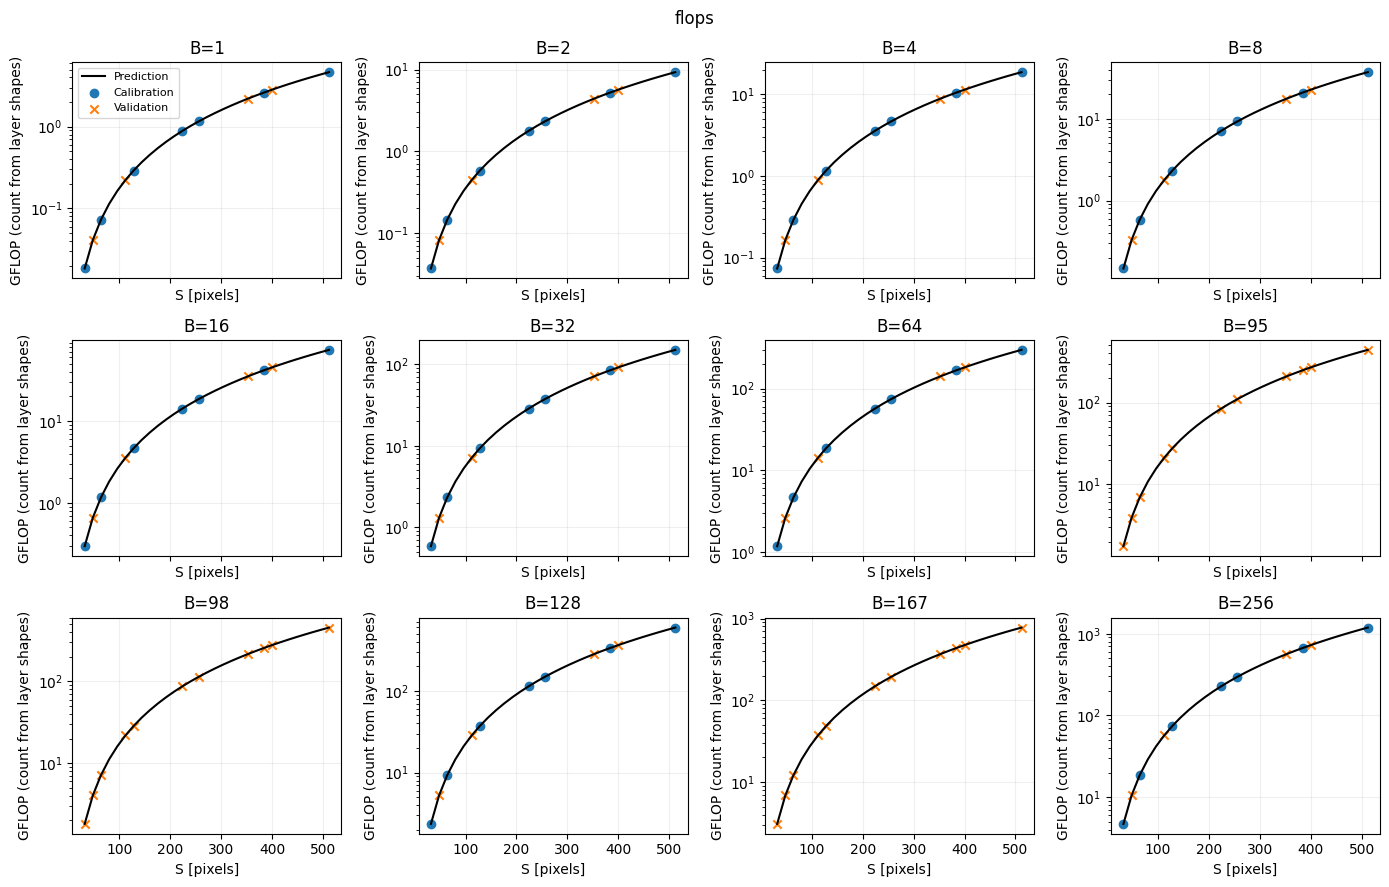

flops validation median absolute error [%]: 0.0


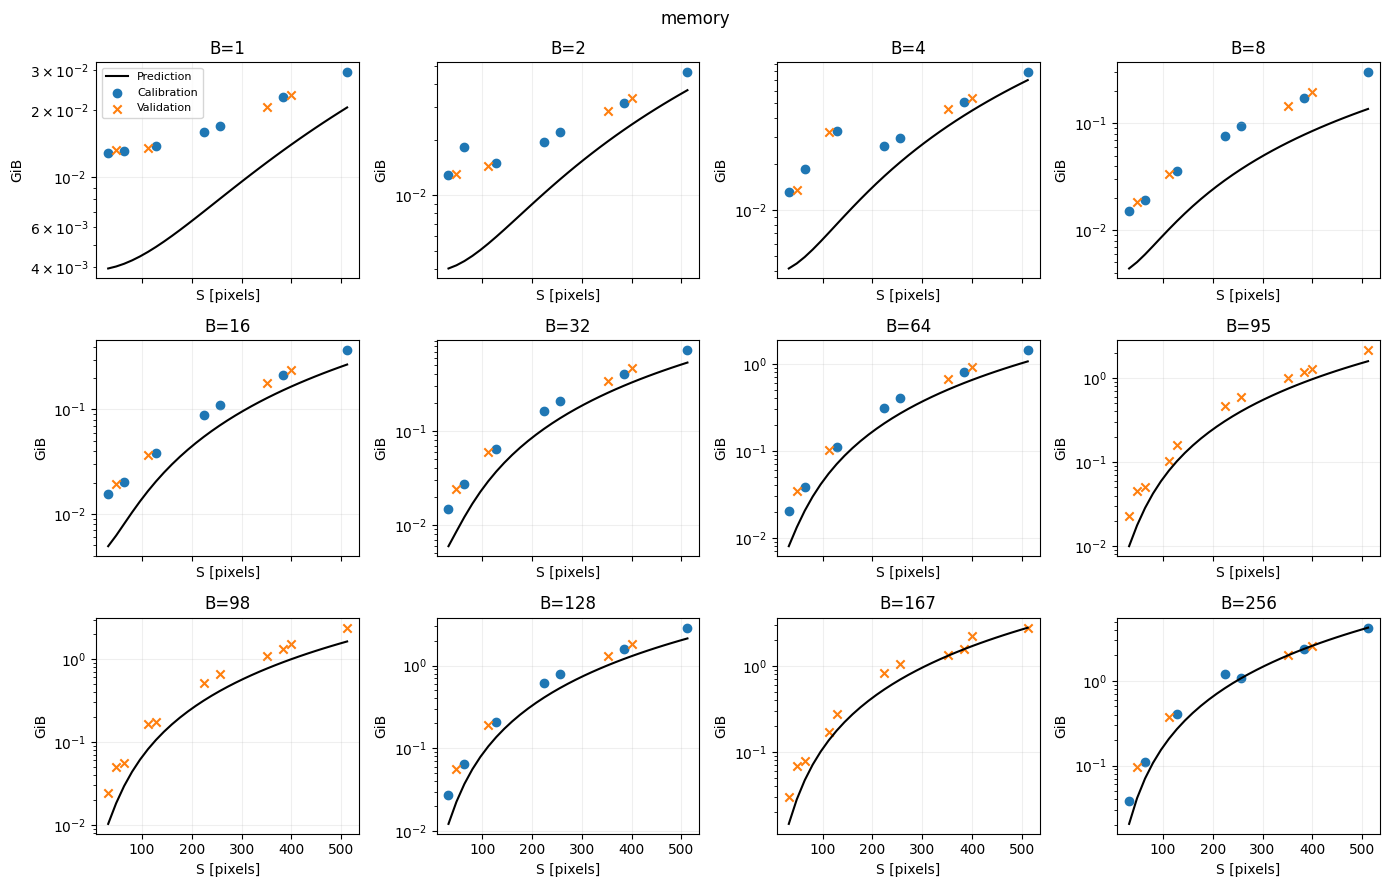

memory validation median absolute error [%]: 38.17


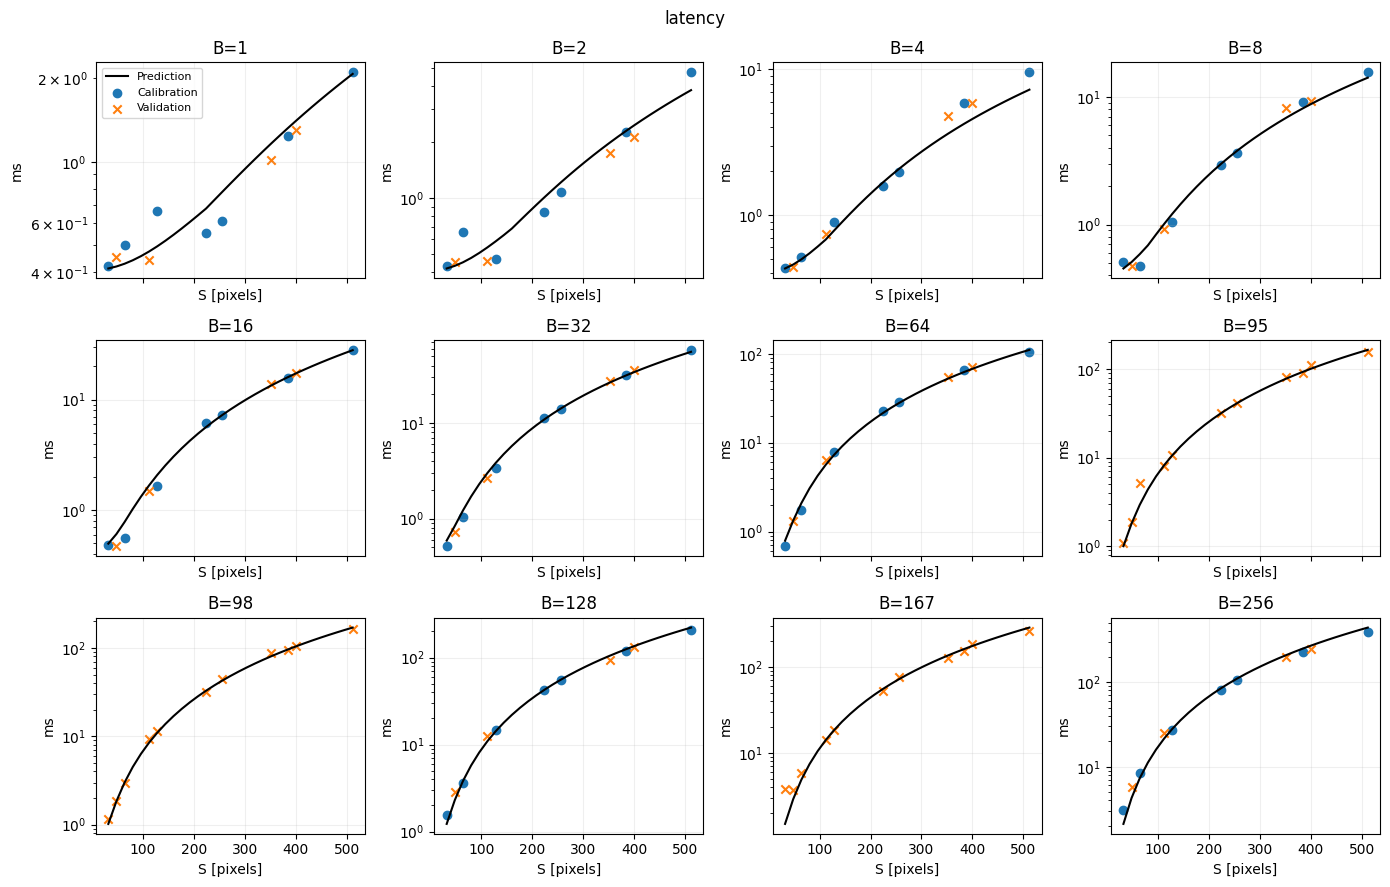

latency validation median absolute error [%]: 7.19


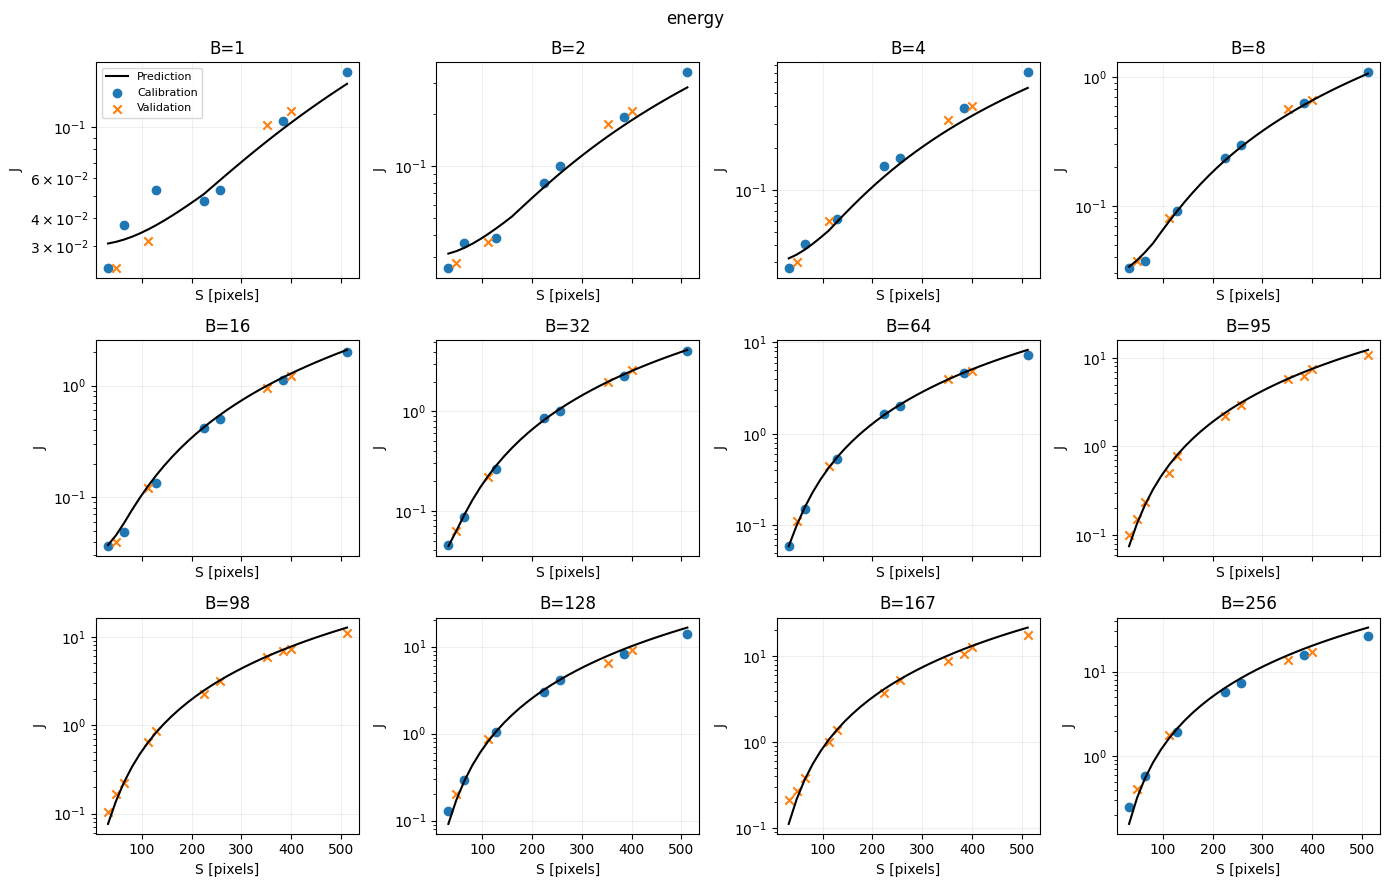

energy validation median absolute error [%]: 9.27
Predicted OOM  False
status              
ok               132


In [7]:
predictions = {
    'flops': (flops, 1e9, 'GFLOP (count from layer shapes)'),
    'memory': (memory, 2**30, 'GiB'),
    'latency': (lambda s, b: latency(s, b, theta), .001, 'ms'),
    'energy': (lambda s, b: energy(s, b, theta_energy), 1, 'J')
}
for name, (predict, scale, unit) in predictions.items():
    fig, axes = plt.subplots(3, 4, figsize=(14, 9), sharex=True)
    for ax, B in zip(axes.flat, batches):
        ss = np.arange(32, 513, 16)
        ax.plot(ss, predict(ss, B)/scale, 'k-', label='Prediction')
        for held, marker, label in [(False, 'o', 'Calibration'), (True, 'x', 'Validation')]:
            part = valid[(valid.B == B) & (valid.is_validation == held)]
            ax.scatter(part.S, part[name]/scale, marker=marker, label=label)
        ax.set(title=f'B={B}', xlabel='S [pixels]', ylabel=unit, yscale='log')
        ax.grid(alpha=.2)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(name)
    fig.tight_layout()
    fig.savefig(f'results/figures/{name}.png', dpi=150)
    plt.show()
    plt.close(fig)
    test = valid[valid.is_validation]
    error = np.abs(predict(test.S.to_numpy(), test.B.to_numpy()) / test[name].to_numpy() - 1)
    print(name, 'validation median absolute error [%]:', round(100*np.median(error), 2))
print(pd.crosstab(df.status, df.predicted_oom, colnames=['Predicted OOM']))


**Граница памяти**

In [9]:
run_memory_search = True
probe_rows = []

@torch.inference_mode()
def probe_memory(B):
    gc.collect()
    torch.cuda.empty_cache()
    free, _ = torch.cuda.mem_get_info()
    budget = free + torch.cuda.memory_allocated()
    row = dict(S=512, B=B, status='ok', memory=None,
               predicted_memory=float(memory(512, B)), available_peak_bytes=budget,
               predicted_oom=bool(memory(512, B) > budget))
    x = y = None
    try:
        x = torch.randn(B, 3, 512, 512, device='cuda', dtype=torch.float32)
        torch.cuda.reset_peak_memory_stats()
        y = model(x)
        torch.cuda.synchronize()
        row['memory'] = torch.cuda.max_memory_allocated()
    except torch.cuda.OutOfMemoryError:
        row['status'] = 'OOM'
    finally:
        x = y = None
        gc.collect()
        torch.cuda.empty_cache()
    probe_rows.append(row)
    Path('results').mkdir(exist_ok=True)
    pd.DataFrame(probe_rows).to_csv('results/oom_probe.csv', index=False)
    print(f'B={B}: {row["status"]}')
    return row['status'] == 'ok'

if run_memory_search:
    lower, upper = 0, 256
    while probe_memory(upper):
        lower, upper = upper, 2 * upper
    while upper - lower > 1:
        middle = (lower + upper) // 2
        if probe_memory(middle):
            lower = middle
        else:
            upper = middle
    print('Наибольший проверенный B без OOM:', lower if lower else 'нет')
    print('Ближайший проверенный B с OOM:', upper)


B=256: ok
B=512: ok
B=1024: OOM
B=768: ok
B=896: OOM
B=832: ok
B=864: ok
B=880: OOM
B=872: OOM
B=868: OOM
B=866: ok
B=867: ok
Наибольший проверенный B без OOM: 867
Ближайший проверенный B с OOM: 868
